# House Price EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## Data Load

In [2]:
# Loadind dataset
df = pd.read_csv("../data/raw/Housing.csv")

## Exploration

In [3]:
df.shape

(545, 13)

In [4]:
df.dtypes

price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object

In [5]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [6]:
df.tail()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [7]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [9]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

## Data Quality Check

In [10]:
# Check for not null
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

> No null values

In [11]:
df.duplicated().sum()

np.int64(0)

> No duplicate values

In [12]:
df_encoded = df.copy()

# Binary columns
binary_cols = ['mainroad','guestroom','basement','hotwaterheating','airconditioning','prefarea']
for col in binary_cols:
    df_encoded[col] = df_encoded[col].map({'yes': 1, 'no': 0})

# Multi-category column
df_encoded = pd.get_dummies(df_encoded, columns=['furnishingstatus'], drop_first=True)

In [13]:
df_encoded.corr()['price'].sort_values(ascending=False)

price                              1.000000
area                               0.535997
bathrooms                          0.517545
airconditioning                    0.452954
stories                            0.420712
parking                            0.384394
bedrooms                           0.366494
prefarea                           0.329777
mainroad                           0.296898
guestroom                          0.255517
basement                           0.187057
hotwaterheating                    0.093073
furnishingstatus_semi-furnished    0.063656
furnishingstatus_unfurnished      -0.280587
Name: price, dtype: float64

In [14]:
important = df_encoded.corr()['price']
important[abs(important) > 0.3]

price              1.000000
area               0.535997
bedrooms           0.366494
bathrooms          0.517545
stories            0.420712
airconditioning    0.452954
parking            0.384394
prefarea           0.329777
Name: price, dtype: float64

In [15]:
df_filtered = df_encoded.drop(columns=[
    'hotwaterheating',
    'furnishingstatus_semi-furnished'
])

## Analysis & Visualization

1. What is the target column? (price?)
2. Which columns are useful features?
3. Are there categorical values? (location, furnishing, etc.)
4. Are there missing values?
5. Are scales very different? (area vs bedrooms)

In [16]:
# 1. What is the target column?
print("Target column: 'price'")
print("Data type:", df['price'].dtype)
print("Min: {}, Max: {}, Mean: {:.2f}".format(
    df['price'].min(),
    df['price'].max(),
    df['price'].mean()
))
print("Standard Deviation:", df['price'].std())


Target column: 'price'
Data type: int64
Min: 1750000, Max: 13300000, Mean: 4766729.25
Standard Deviation: 1870439.6156573922


In [17]:
# 2. Which columns are useful features?
print("\nAll correlations with price:")
print(df_encoded.corr()['price'].sort_values(ascending=False))
print("\nFeatures with |correlation| > 0.3 (strong relationships):")
print(important[abs(important) > 0.3].sort_values(ascending=False))
print(f"\nSelected features for modeling: {df_filtered.columns.tolist()}")



All correlations with price:
price                              1.000000
area                               0.535997
bathrooms                          0.517545
airconditioning                    0.452954
stories                            0.420712
parking                            0.384394
bedrooms                           0.366494
prefarea                           0.329777
mainroad                           0.296898
guestroom                          0.255517
basement                           0.187057
hotwaterheating                    0.093073
furnishingstatus_semi-furnished    0.063656
furnishingstatus_unfurnished      -0.280587
Name: price, dtype: float64

Features with |correlation| > 0.3 (strong relationships):
price              1.000000
area               0.535997
bathrooms          0.517545
airconditioning    0.452954
stories            0.420712
parking            0.384394
bedrooms           0.366494
prefarea           0.329777
Name: price, dtype: float64

Selected featu

In [18]:
# 3. Are there categorical values?
print(f"{df['furnishingstatus'].unique()}")
print(f"(converted using one-hot encoding, drop_first=True)")

print("\nValue counts for furnishingstatus:")
print(df['furnishingstatus'].value_counts())


<StringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str
(converted using one-hot encoding, drop_first=True)

Value counts for furnishingstatus:
furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64


In [19]:
# 4. Are there missing values?
print("Null values per column:")
print(df.isnull().sum())
print("\nTotal null values:", df.isnull().sum().sum())
print("\nNull values in encoded dataset:", df_encoded.isnull().sum().sum())


Null values per column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Total null values: 0

Null values in encoded dataset: 0


In [20]:
# 5. Are scales very different?
print("\nNumerical features statistics:")
print(df_filtered.describe().T[['min', 'max', 'mean', 'std']])



Numerical features statistics:
                       min         max          mean           std
price            1750000.0  13300000.0  4.766729e+06  1.870440e+06
area                1650.0     16200.0  5.150541e+03  2.170141e+03
bedrooms               1.0         6.0  2.965138e+00  7.380639e-01
bathrooms              1.0         4.0  1.286239e+00  5.024696e-01
stories                1.0         4.0  1.805505e+00  8.674925e-01
mainroad               0.0         1.0  8.587156e-01  3.486347e-01
guestroom              0.0         1.0  1.779817e-01  3.828487e-01
basement               0.0         1.0  3.504587e-01  4.775519e-01
airconditioning        0.0         1.0  3.155963e-01  4.651799e-01
parking                0.0         3.0  6.935780e-01  8.615858e-01
prefarea               0.0         1.0  2.348624e-01  4.243022e-01


In [21]:
print("\nFeature ranges (max - min):")
for col in df_filtered.select_dtypes(include=[np.number]).columns:
    if col != 'price':
        range_val = df_filtered[col].max() - df_filtered[col].min()
        print(f"  {col:25s}: {range_val:10.2f}")


Feature ranges (max - min):
  area                     :   14550.00
  bedrooms                 :       5.00
  bathrooms                :       3.00
  stories                  :       3.00
  mainroad                 :       1.00
  guestroom                :       1.00
  basement                 :       1.00
  airconditioning          :       1.00
  parking                  :       3.00
  prefarea                 :       1.00


## Data Preparation & Normalization

In [22]:
# Separate features and target
X = df_filtered.drop('price', axis=1)
y = df_filtered['price'].values

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features (important for gradient descent!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining set:", X_train_scaled.shape)
print("Test set:", X_test_scaled.shape)
print("Feature means (should be ~0):", X_train_scaled.mean(axis=0).round(4))
print("Feature stds (should be ~1):", X_train_scaled.std(axis=0).round(4))


Features shape: (545, 11)
Target shape: (545,)

Training set: (436, 11)
Test set: (109, 11)
Feature means (should be ~0): [ 0.  0.  0.  0.  0.  0. -0.  0. -0. -0. -0.]
Feature stds (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Linear Regression from Scratch with Gradient Descent

In [23]:
class LinearRegressionGD:    
    def __init__(self, learning_rate=0.01, iterations=1000, random_state=42):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.cost_history = []
        
    def fit(self, X, y):
        """Train the model using gradient descent"""
        np.random.seed(self.random_state)
        
        # Initialize weights and bias
        m, n = X.shape
        self.weights = np.random.randn(n) * 0.01
        self.bias = 0
        
        # Gradient Descent Loop
        for iteration in range(self.iterations):
            # Predictions
            y_pred = X.dot(self.weights) + self.bias
            
            # Calculate errors
            errors = y_pred - y
            
            # Cost function (MSE)
            cost = (1 / (2 * m)) * np.sum(errors ** 2)
            self.cost_history.append(cost)
            
            # Gradients
            dw = (1 / m) * X.T.dot(errors)
            db = (1 / m) * np.sum(errors)
            
            # Update weights and bias
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
            
            # Print progress every 100 iterations
            if (iteration + 1) % 100 == 0 or iteration == 0:
                print(f"Iteration {iteration + 1}/{self.iterations}, Cost: {cost:.6f}")
        
        return self
    
    def predict(self, X):
        """Make predictions"""
        return X.dot(self.weights) + self.bias

print("LinearRegressionGD class created")


LinearRegressionGD class created


In [24]:
# Train the model - Linear Regression with Gradient Descent
model_gd = LinearRegressionGD(learning_rate=0.1, iterations=1000, random_state=42)
model_gd.fit(X_train_scaled, y_train)

# Make predictions
y_train_pred_gd = model_gd.predict(X_train_scaled)
y_test_pred_gd = model_gd.predict(X_test_scaled)

# Calculate metrics
train_mse_gd = np.mean((y_train - y_train_pred_gd) ** 2)
test_mse_gd = np.mean((y_test - y_test_pred_gd) ** 2)

train_rmse_gd = np.sqrt(train_mse_gd)
test_rmse_gd = np.sqrt(test_mse_gd)

train_r2_gd = 1 - (np.sum((y_train - y_train_pred_gd) ** 2) / np.sum((y_train - np.mean(y_train)) ** 2))
test_r2_gd = 1 - (np.sum((y_test - y_test_pred_gd) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))

print("\nCustom Linear Regression (Gradient Descent) Results:")
print("Train RMSE :", train_rmse_gd)
print("Test RMSE  :", test_rmse_gd)
print("Train R²   :", train_r2_gd)
print("Test R²    :", test_r2_gd)


Iteration 1/1000, Cost: 12617396170916.177734
Iteration 100/1000, Cost: 496271844060.931091
Iteration 200/1000, Cost: 496267557059.407227
Iteration 300/1000, Cost: 496267555744.763916
Iteration 400/1000, Cost: 496267555744.343933
Iteration 500/1000, Cost: 496267555744.343872
Iteration 600/1000, Cost: 496267555744.343933
Iteration 700/1000, Cost: 496267555744.343872
Iteration 800/1000, Cost: 496267555744.343872
Iteration 900/1000, Cost: 496267555744.343933
Iteration 1000/1000, Cost: 496267555744.343933

Custom Linear Regression (Gradient Descent) Results:
Train RMSE : 996260.5640537458
Test RMSE  : 1341870.193526012
Train R²   : 0.6781028847759596
Test R²    : 0.6437648447817442


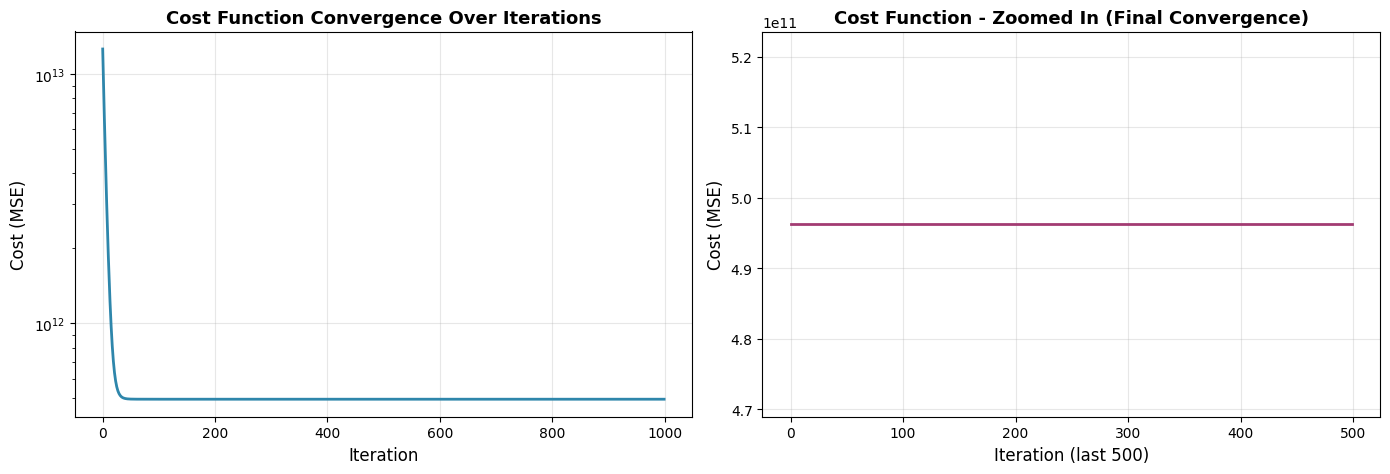


Initial Cost: 12617396170916.177734
Final Cost:   496267555744.343933
Cost Reduction: 96.07%


In [25]:
# Visualize Cost Function Convergence
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Full cost history
axes[0].plot(model_gd.cost_history, linewidth=2, color='#2E86AB')
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('Cost (MSE)', fontsize=12)
axes[0].set_title('Cost Function Convergence Over Iterations', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')

# Plot 2: Last 500 iterations (zoomed in)
axes[1].plot(model_gd.cost_history[-500:], linewidth=2, color='#A23B72')
axes[1].set_xlabel('Iteration (last 500)', fontsize=12)
axes[1].set_ylabel('Cost (MSE)', fontsize=12)
axes[1].set_title('Cost Function - Zoomed In (Final Convergence)', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/figures/cost_function_convergence.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nInitial Cost: {model_gd.cost_history[0]:.6f}")
print(f"Final Cost:   {model_gd.cost_history[-1]:.6f}")
print(f"Cost Reduction: {((model_gd.cost_history[0] - model_gd.cost_history[-1]) / model_gd.cost_history[0] * 100):.2f}%")


## Verification with Scikit-Learn

In [26]:
# Train sklearn model for comparison
model_sklearn = SklearnLinearRegression()
model_sklearn.fit(X_train_scaled, y_train)

# Predictions
y_train_pred_sklearn = model_sklearn.predict(X_train_scaled)
y_test_pred_sklearn = model_sklearn.predict(X_test_scaled)

# Metrics
train_mse_sklearn = mean_squared_error(y_train, y_train_pred_sklearn)
test_mse_sklearn = mean_squared_error(y_test, y_test_pred_sklearn)
train_rmse_sklearn = np.sqrt(train_mse_sklearn)
test_rmse_sklearn = np.sqrt(test_mse_sklearn)
train_r2_sklearn = r2_score(y_train, y_train_pred_sklearn)
test_r2_sklearn = r2_score(y_test, y_test_pred_sklearn)

print("Scikit-Learn Linear Regression Results:")
print(f"  Train RMSE: {train_rmse_sklearn:.4f}")
print(f"  Test RMSE:  {test_rmse_sklearn:.4f}")
print(f"  Train R²:   {train_r2_sklearn:.4f}")
print(f"  Test R²:    {test_r2_sklearn:.4f}")

# Comparison
print("\nCOMPARISON: Custom Gradient Descent vs Scikit-Learn")
print(f"{'Metric':<20} {'Custom GD':<15} {'Sklearn':<15} {'Difference':<15}")
print(f"{'Train RMSE':<20} {train_rmse_gd:<15.4f} {train_rmse_sklearn:<15.4f} {abs(train_rmse_gd - train_rmse_sklearn):<15.4f}")
print(f"{'Test RMSE':<20} {test_rmse_gd:<15.4f} {test_rmse_sklearn:<15.4f} {abs(test_rmse_gd - test_rmse_sklearn):<15.4f}")
print(f"{'Train R²':<20} {train_r2_gd:<15.4f} {train_r2_sklearn:<15.4f} {abs(train_r2_gd - train_r2_sklearn):<15.4f}")
print(f"{'Test R²':<20} {test_r2_gd:<15.4f} {test_r2_sklearn:<15.4f} {abs(test_r2_gd - test_r2_sklearn):<15.4f}")


Scikit-Learn Linear Regression Results:
  Train RMSE: 996260.5641
  Test RMSE:  1341870.1935
  Train R²:   0.6781
  Test R²:    0.6438

COMPARISON: Custom Gradient Descent vs Scikit-Learn
Metric               Custom GD       Sklearn         Difference     
Train RMSE           996260.5641     996260.5641     0.0000         
Test RMSE            1341870.1935    1341870.1935    0.0000         
Train R²             0.6781          0.6781          0.0000         
Test R²              0.6438          0.6438          0.0000         


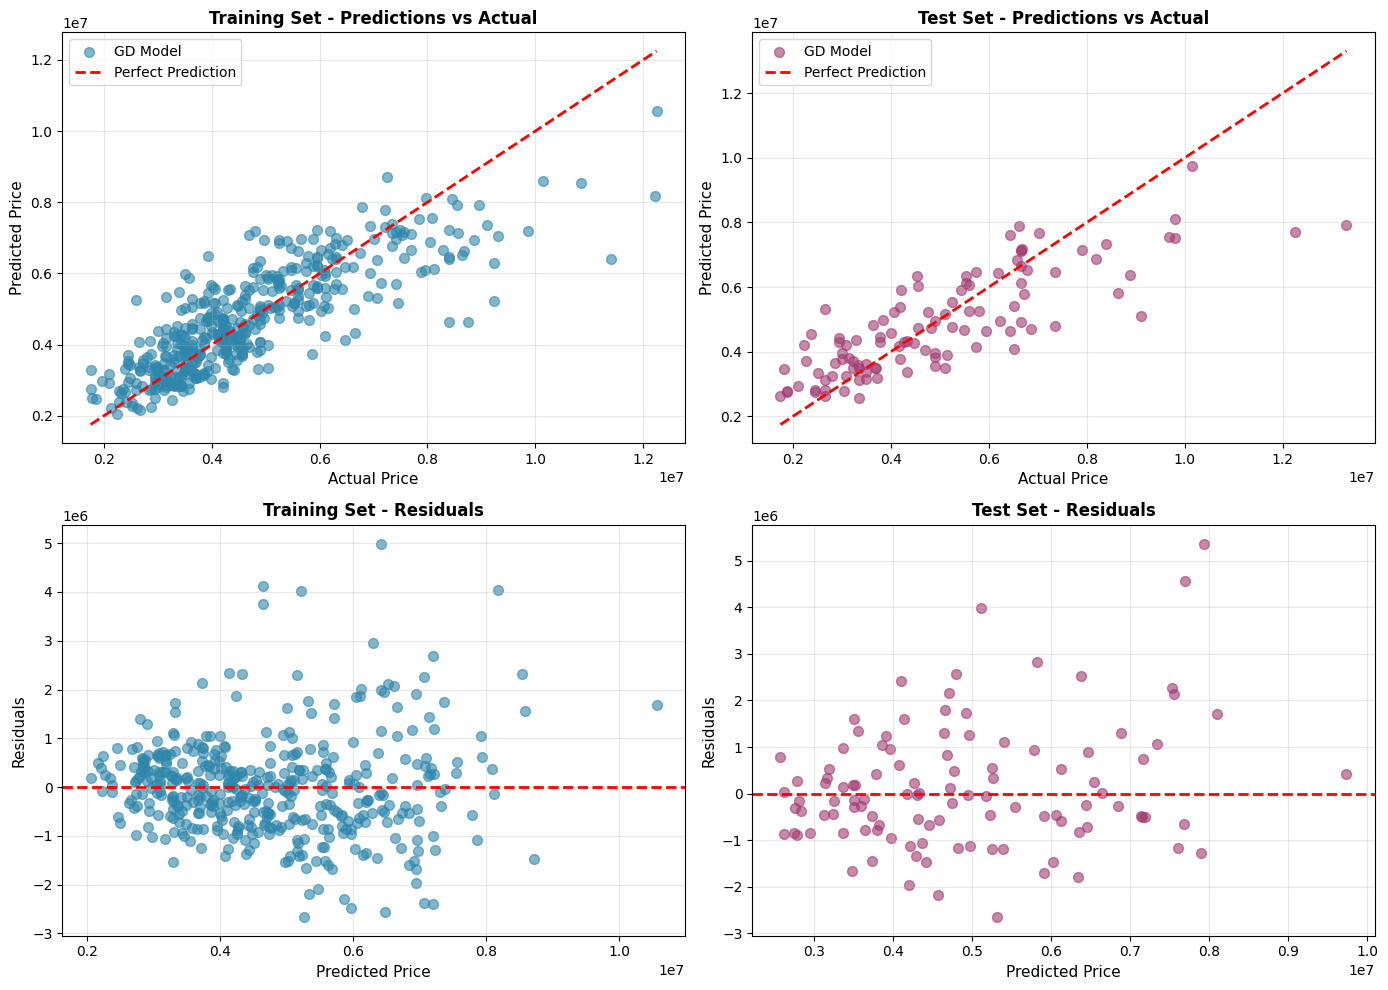

In [27]:
# Visualize Predictions vs Actual
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Train predictions
axes[0, 0].scatter(y_train, y_train_pred_gd, alpha=0.6, s=50, color='#2E86AB', label='GD Model')
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0, 0].set_xlabel('Actual Price', fontsize=11)
axes[0, 0].set_ylabel('Predicted Price', fontsize=11)
axes[0, 0].set_title('Training Set - Predictions vs Actual', fontsize=12, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Test predictions
axes[0, 1].scatter(y_test, y_test_pred_gd, alpha=0.6, s=50, color='#A23B72', label='GD Model')
axes[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0, 1].set_xlabel('Actual Price', fontsize=11)
axes[0, 1].set_ylabel('Predicted Price', fontsize=11)
axes[0, 1].set_title('Test Set - Predictions vs Actual', fontsize=12, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Residuals - Training
train_residuals_gd = y_train - y_train_pred_gd
axes[1, 0].scatter(y_train_pred_gd, train_residuals_gd, alpha=0.6, s=50, color='#2E86AB')
axes[1, 0].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1, 0].set_xlabel('Predicted Price', fontsize=11)
axes[1, 0].set_ylabel('Residuals', fontsize=11)
axes[1, 0].set_title('Training Set - Residuals', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Residuals - Test
test_residuals_gd = y_test - y_test_pred_gd
axes[1, 1].scatter(y_test_pred_gd, test_residuals_gd, alpha=0.6, s=50, color='#A23B72')
axes[1, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1, 1].set_xlabel('Predicted Price', fontsize=11)
axes[1, 1].set_ylabel('Residuals', fontsize=11)
axes[1, 1].set_title('Test Set - Residuals', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/figures/model_predictions_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
